In [1]:
import pandas as pd
import numpy as np

pd.set_option("display.max_columns", None)

df = pd.read_csv("../data/raw/train.csv")

df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [2]:
print("Dataset shape:")
print(df.shape)

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

Dataset shape:
(891, 12)

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB

Missing values:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin

In [3]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [4]:
print("Sex values:")
print(df["Sex"].value_counts())

print("\nEmbarked values:")
print(df["Embarked"].value_counts())

print("\nPclass values:")
print(df["Pclass"].value_counts())

Sex values:
Sex
male      577
female    314
Name: count, dtype: int64

Embarked values:
Embarked
S    644
C    168
Q     77
Name: count, dtype: int64

Pclass values:
Pclass
3    491
1    216
2    184
Name: count, dtype: int64


In [5]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [6]:
missing = df.isnull().sum()

missing = missing[missing > 0]

print("Columns containing missing values:")
print(missing)

Columns containing missing values:
Age         177
Cabin       687
Embarked      2
dtype: int64


In [ ]:
# Make a copy before cleaning
df_clean = df.copy()

# Fill missing Age values with the median
df_clean["Age"] = df_clean["Age"].fillna(df_clean["Age"].median())

# Fill missing Embarked values with the mode
df_clean["Embarked"] = df_clean["Embarked"].fillna(df_clean["Embarked"].mode()[0])


# Fill missing Cabin values with "Unknown"
df_clean["Cabin"] = df_clean["Cabin"].fillna("Unknown")

print("Missing values after cleaning:")
print(df_clean.isnull().sum())

Missing values after cleaning:
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Cabin          0
Embarked       0
dtype: int64


In [8]:
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          891 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        891 non-null    str    
 11  Embarked     891 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [9]:
# Validate the data types of important columns

print("Numeric columns:")
print(df_clean[["PassengerId", "Survived", "Pclass", "Age", "SibSp", "Parch", "Fare"]].dtypes)

print("\nText columns:")
print(df_clean[["Name", "Sex", "Ticket", "Cabin", "Embarked"]].dtypes)

Numeric columns:
PassengerId      int64
Survived         int64
Pclass           int64
Age            float64
SibSp            int64
Parch            int64
Fare           float64
dtype: object

Text columns:
Name        str
Sex         str
Ticket      str
Cabin       str
Embarked    str
dtype: object


In [10]:
print("===== FINAL DATA QUALITY CHECK =====")

print("Rows:", df_clean.shape[0])
print("Columns:", df_clean.shape[1])

print("\nTotal missing values:", df_clean.isnull().sum().sum())

print("Duplicate rows:", df_clean.duplicated().sum())

print("\nData types:")
print(df_clean.dtypes)

===== FINAL DATA QUALITY CHECK =====
Rows: 891
Columns: 12

Total missing values: 0
Duplicate rows: 0

Data types:
PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str
dtype: object


In [11]:
import os

# Create the cleaned-data folder if it does not exist
os.makedirs("../data/cleaned", exist_ok=True)

# Save the cleaned dataset
output_path = "../data/cleaned/titanic_cleaned.csv"

df_clean.to_csv(output_path, index=False)

print("Cleaned dataset saved successfully.")
print("File location:", output_path)

Cleaned dataset saved successfully.
File location: ../data/cleaned/titanic_cleaned.csv


In [12]:
# Load the saved cleaned dataset to verify the file

cleaned_df = pd.read_csv("../data/cleaned/titanic_cleaned.csv")

print("Cleaned dataset loaded successfully.")
print("Shape:", cleaned_df.shape)

print("\nMissing values:")
print(cleaned_df.isnull().sum().sum())

cleaned_df.head()

Cleaned dataset loaded successfully.
Shape: (891, 12)

Missing values:
0


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,Unknown,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,Unknown,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,Unknown,S


## Data Cleaning Assumptions

The following assumptions were made during data preparation:

1. Missing `Age` values were replaced with the median age because `Age` is a
   numerical variable and the median is less affected by extreme values.

2. Missing `Embarked` values were replaced with the most frequent value
   (mode) because `Embarked` is a categorical variable.

3. Missing `Cabin` values were replaced with `Unknown`. The records were
   retained because a missing cabin value does not mean that the passenger
   record is invalid.

4. Duplicate records were checked before and after preprocessing.

5. Existing data types were inspected and verified. Numerical variables were
   retained as numerical types and text variables were retained as string
   types.

6. The original dataset was not modified. Cleaning was performed on a copy
   named `df_clean`.

7. The cleaned dataset was saved separately as
   `data/cleaned/titanic_cleaned.csv`.

## Final Data Preparation Result

The Titanic dataset was successfully prepared for further data-science work.

### Dataset Before Cleaning

- 891 rows
- 12 columns
- Missing values were present in `Age`, `Cabin`, and `Embarked`

### Dataset After Cleaning

- 891 rows
- 12 columns
- 0 missing values
- 0 duplicate rows
- Data types verified
- Cleaned dataset saved separately

The original raw dataset was preserved, and all preprocessing was performed
on a separate copy of the data.

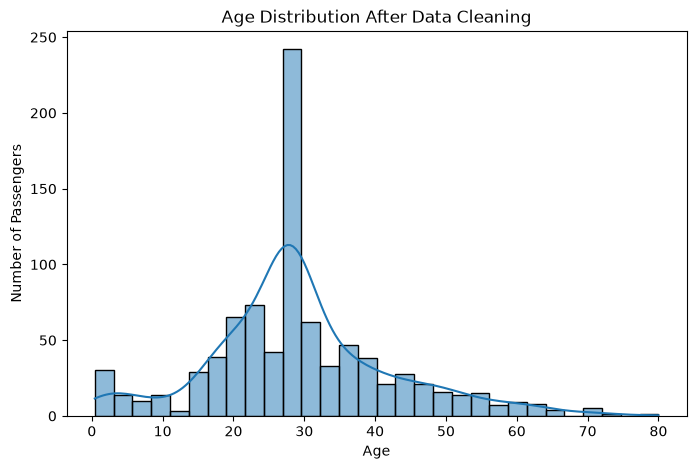

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.histplot(data=cleaned_df, x="Age", bins=30, kde=True)

plt.title("Age Distribution After Data Cleaning")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")

plt.show()